In [2]:
pip install pandas numpy scikit-learn matplotlib seaborn

Note: you may need to restart the kernel to use updated packages.


In [3]:
pip install transformers datasets torch accelerate

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 608.3/608.3 kB 15.0 MB/s  0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 37.3/37.3 MB 37.0 MB/s  0:00:01 38.7 MB/s eta 0:00:01
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 6/6 [accelerate] 5/6 [accelerate]sets]
Note: you may need to restart the kernel to use updated packages.


In [6]:
from datasets import load_dataset

# Load SST-2 dataset
dataset = load_dataset("nyu-mll/glue", "sst2")

train_dataset = dataset["train"]
validation_dataset = dataset["validation"]

print("Training samples:", len(train_dataset))
print("Validation samples:", len(validation_dataset))

print(train_dataset[0])

Generating train split: 100%|█| 67349/67349 [00:00<00:00, 483602.99 examples/s]
Generating validation split: 100%|█| 872/872 [00:00<00:00, 276910.44 examples/s
Generating test split: 100%|████| 1821/1821 [00:00<00:00, 586082.53 examples/s]

Training samples: 67349
Validation samples: 872
{'sentence': 'hide new secretions from the parental units ', 'label': 0, 'idx': 0}


In [8]:
# Reproducible sampling
train_sample = train_dataset.shuffle(seed=42).select(range(20000))

validation_sample = validation_dataset.shuffle(
    seed=42
).select(range(500))

X_train = train_sample["sentence"]
y_train = train_sample["label"]

X_test = validation_sample["sentence"]
y_test = validation_sample["label"]

In [23]:
import time

from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.linear_model import LogisticRegression
from sklearn.pipeline import Pipeline

# Build TF-IDF + Logistic Regression
tfidf_model = Pipeline([
    (
        "tfidf",
        TfidfVectorizer(
            max_features=20000,
            ngram_range=(1, 2),
            stop_words="english"
        )
    ),
    (
        "classifier",
        LogisticRegression(
            max_iter=1000,
            random_state=42
        )
    )
])

# Train the model
start_time = time.perf_counter()

tfidf_model.fit(X_train, y_train)

tfidf_training_time = time.perf_counter() - start_time

print(f"TF-IDF training time: {tfidf_training_time:.3f} seconds")

TF-IDF training time: 1.001 seconds


In [24]:
import torch

from transformers import pipeline

# Automatically select GPU if available
device = 0 if torch.cuda.is_available() else -1

sentiment_pipeline = pipeline(
    task="sentiment-analysis",
    model="distilbert-base-uncased-finetuned-sst-2-english",
    device=device
)

print("Device:", "GPU" if device == 0 else "CPU")

Loading weights: 100%|████████████████████| 104/104 [00:00<00:00, 11929.32it/s]


Device: CPU


In [25]:
sample_sentences = [
    "The movie was absolutely wonderful.",
    "The movie was not good at all.",
    "The acting was okay, but the story was disappointing."
]

results = sentiment_pipeline(sample_sentences)

for sentence, result in zip(sample_sentences, results):
    print(sentence)
    print(result)
    print()

The movie was absolutely wonderful.
{'label': 'POSITIVE', 'score': 0.9998785257339478}

The movie was not good at all.
{'label': 'NEGATIVE', 'score': 0.9997633099555969}

The acting was okay, but the story was disappointing.
{'label': 'NEGATIVE', 'score': 0.9991193413734436}



In [26]:
# Measure prediction latency, including TF-IDF vectorization
start_time = time.perf_counter()

tfidf_predictions = tfidf_model.predict(X_test)

tfidf_prediction_time = time.perf_counter() - start_time

print("TF-IDF prediction time:",
      round(tfidf_prediction_time, 4), "seconds")

TF-IDF prediction time: 0.0442 seconds


In [28]:

import time
import torch
import pandas as pd
from transformers import pipeline

# 1. Clean the test dataset
# Handle Pandas Series, NumPy arrays, and Python lists
if isinstance(X_test, pd.Series):
    X_test_clean = X_test.fillna("").astype(str).tolist()
else:
    X_test_clean = [
        "" if pd.isna(text) else str(text)
        for text in X_test
    ]

# Optional: remove leading/trailing whitespace
X_test_clean = [text.strip() for text in X_test_clean]

# 2. Automatically select GPU if available
device = 0 if torch.cuda.is_available() else -1

sentiment_pipeline = pipeline(
    task="sentiment-analysis",
    model="distilbert-base-uncased-finetuned-sst-2-english",
    device=device
)

print("Device:", "GPU" if device == 0 else "CPU")

# 3. Warm up the model before measuring latency
sentiment_pipeline(
    X_test_clean[:5],
    truncation=True
)

# 4. Measure inference latency
start_time = time.perf_counter()

transformer_results = sentiment_pipeline(
    X_test_clean,
    batch_size=32,
    truncation=True
)

transformer_prediction_time = time.perf_counter() - start_time

# 5. Convert labels to binary values
transformer_predictions = [
    1 if result["label"] == "POSITIVE" else 0
    for result in transformer_results
]

# 6. Extract confidence scores
transformer_confidence = [
    result["score"]
    for result in transformer_results
]

print(
    "Transformer prediction time:",
    round(transformer_prediction_time, 4),
    "seconds"
)

print("Number of predictions:", len(transformer_predictions))


Loading weights: 100%|█████████████████████| 104/104 [00:00<00:00, 5937.06it/s]


Device: CPU
Transformer prediction time: 3.369 seconds
Number of predictions: 500


In [29]:
# Warm up the model before measuring latency
sentiment_pipeline(X_test[:5])

start_time = time.perf_counter()

transformer_results = sentiment_pipeline(
    X_test,
    batch_size=32,
    truncation=True
)

transformer_prediction_time = time.perf_counter() - start_time

# Convert labels to binary values
transformer_predictions = [
    1 if result["label"] == "POSITIVE" else 0
    for result in transformer_results
]

transformer_confidence = [
    result["score"]
    for result in transformer_results
]

print(
    "Transformer prediction time:",
    round(transformer_prediction_time, 4),
    "seconds"
)

ValueError: text input must be of type `str` (single example), `list[str]` (batch or single pretokenized example) or `list[list[str]]` (batch of pretokenized examples) or `list[tuple[list[str], list[str]]]` (batch of pretokenized sequence pairs).

In [30]:
import pandas as pd

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    classification_report
)

def evaluate_model(y_true, predictions, model_name):

    return {
        "Model": model_name,
        "Accuracy": accuracy_score(y_true, predictions),
        "Precision": precision_score(y_true, predictions),
        "Recall": recall_score(y_true, predictions),
        "F1 Score": f1_score(y_true, predictions)
    }


results = [
    evaluate_model(
        y_test,
        tfidf_predictions,
        "TF-IDF + Logistic Regression"
    ),

    evaluate_model(
        y_test,
        transformer_predictions,
        "DistilBERT Transformer"
    )
]

results_df = pd.DataFrame(results)

print(results_df.round(4))

                          Model  Accuracy  Precision  Recall  F1 Score
0  TF-IDF + Logistic Regression     0.772     0.7410  0.8659    0.7986
1        DistilBERT Transformer     0.908     0.8996  0.9272    0.9132


In [31]:
print("TF-IDF Classification Report")

print(
    classification_report(
        y_test,
        tfidf_predictions,
        target_names=["Negative", "Positive"]
    )
)

print("Transformer Classification Report")

print(
    classification_report(
        y_test,
        transformer_predictions,
        target_names=["Negative", "Positive"]
    )
)

TF-IDF Classification Report
              precision    recall  f1-score   support

    Negative       0.82      0.67      0.74       239
    Positive       0.74      0.87      0.80       261

    accuracy                           0.77       500
   macro avg       0.78      0.77      0.77       500
weighted avg       0.78      0.77      0.77       500

Transformer Classification Report
              precision    recall  f1-score   support

    Negative       0.92      0.89      0.90       239
    Positive       0.90      0.93      0.91       261

    accuracy                           0.91       500
   macro avg       0.91      0.91      0.91       500
weighted avg       0.91      0.91      0.91       500



In [32]:
comparison_df = pd.DataFrame({
    "sentence": X_test,
    "actual": y_test,
    "tfidf_prediction": tfidf_predictions,
    "transformer_prediction": transformer_predictions,
    "transformer_confidence": transformer_confidence
})

# Identify disagreements
disagreements = comparison_df[
    comparison_df["tfidf_prediction"]
    != comparison_df["transformer_prediction"]
].copy()

print("Total disagreements:", len(disagreements))

print(
    disagreements[
        [
            "sentence",
            "actual",
            "tfidf_prediction",
            "transformer_prediction",
            "transformer_confidence"
        ]
    ].head(15).to_string(index=False)
)

Total disagreements: 112
                                                                                                                                                                                                          sentence  actual  tfidf_prediction  transformer_prediction  transformer_confidence
                                                                                                                                             the film tunes into a grief that could lead a man across centuries .        1                 1                       0                0.963116
                                              you 'll gasp appalled and laugh outraged and possibly , watching the spectacle of a promising young lad treading desperately in a nasty sea , shed an errant tear .        1                 1                       0                0.949698
                                                                   fresnadillo 's dark and jolting images have a way of 

In [33]:
disagreements["tfidf_correct"] = (
    disagreements["tfidf_prediction"]
    == disagreements["actual"]
)

disagreements["transformer_correct"] = (
    disagreements["transformer_prediction"]
    == disagreements["actual"]
)

print(
    disagreements[
        [
            "sentence",
            "actual",
            "tfidf_prediction",
            "transformer_prediction",
            "tfidf_correct",
            "transformer_correct"
        ]
    ].head(20).to_string(index=False)
)

                                                                                                                                                                                                          sentence  actual  tfidf_prediction  transformer_prediction  tfidf_correct  transformer_correct
                                                                                                                                             the film tunes into a grief that could lead a man across centuries .        1                 1                       0           True                False
                                              you 'll gasp appalled and laugh outraged and possibly , watching the spectacle of a promising young lad treading desperately in a nasty sea , shed an errant tear .        1                 1                       0           True                False
                                                                   fresnadillo 's dark and jolting images hav

In [34]:
num_samples = len(X_test)

latency_df = pd.DataFrame([
    {
        "Model": "TF-IDF",
        "Total Time (s)": tfidf_prediction_time,
        "Average Latency (ms/sample)": (
            tfidf_prediction_time / num_samples * 1000
        ),
        "Throughput (samples/s)": (
            num_samples / tfidf_prediction_time
        )
    },
    {
        "Model": "DistilBERT",
        "Total Time (s)": transformer_prediction_time,
        "Average Latency (ms/sample)": (
            transformer_prediction_time / num_samples * 1000
        ),
        "Throughput (samples/s)": (
            num_samples / transformer_prediction_time
        )
    }
])

print(latency_df.round(3))

        Model  Total Time (s)  Average Latency (ms/sample)  \
0      TF-IDF           0.044                        0.088   
1  DistilBERT           3.369                        6.738   

   Throughput (samples/s)  
0               11319.505  
1                 148.412  


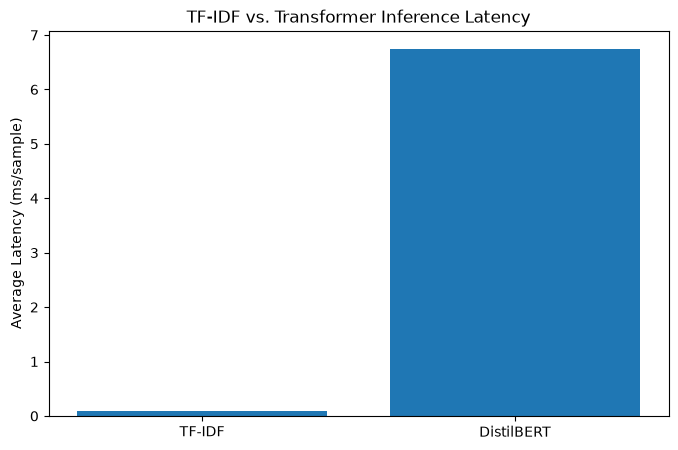

In [35]:
import matplotlib.pyplot as plt

plt.figure(figsize=(8, 5))

plt.bar(
    latency_df["Model"],
    latency_df["Average Latency (ms/sample)"]
)

plt.ylabel("Average Latency (ms/sample)")
plt.title("TF-IDF vs. Transformer Inference Latency")

plt.show()

In [36]:
final_comparison = results_df.merge(
    latency_df,
    on="Model"
)

print(final_comparison.round(4))

Empty DataFrame
Columns: [Model, Accuracy, Precision, Recall, F1 Score, Total Time (s), Average Latency (ms/sample), Throughput (samples/s)]
Index: []


In [37]:
# Save model comparison
final_comparison.to_csv(
    "problem22_model_comparison.csv",
    index=False
)

# Save disagreement examples
disagreements.to_csv(
    "problem22_disagreements.csv",
    index=False
)

print("Results saved successfully.")

Results saved successfully.
